In [2]:
import pandas as pd
df = pd.read_excel('Mental_Health_Dataset_Version_2 (1).xlsx')
df.shape #without print() it wouldnt have worked out but in jupyter if it is the last line , it will be printed.

(100, 22)

In [3]:
for i , col in enumerate(df.columns, start=1): #to start the index from 1 use, enumerate(df.columns, start=1). df.columns is a pandas Index object.
    print(i, col)

1 Timestamp
2 Consent Agreement: I confirm that I am at least 18 years old and consent to my anonymized data being collected for academic research and non-clinical algorithm development.
3 Gender
4 Current Academic Year
5 Current Living Arrangement
6 Average Daily Academic Screen Time (Hours)
7 Average Daily Entertainment / Social Screen Time (Hours)
8 Over the past 2 weeks, how often have you felt nervous, anxious, or excessively stressed?
9 How frequently do racing thoughts or repetitive worry delay your sleep or relaxation?
10 How often do you experience difficulty concentrating or mental slowness during study sessions?
11 How often over the past month have you felt a lack of energy, interest, or motivation in daily routines?
12 How frequently do you experience sudden irritability or mental exhaustion by the end of the day?
13 On average, how many hours of uninterrupted sleep do you get per night?
14 Briefly describe the main factors (e.g., exams, habits, diet, screen time) that aff

In [4]:
new_names = [ #what if i used tuples or sets instead?
    "submitted_at", "consent", "gender", "academic_year", "living_arrangement",
    "academic_screen_raw", "entertainment_screen_raw",
    "stress_anxious", "racing_thoughts", "concentration", "low_motivation", "irritability",
    "sleep_raw", "main_factors", "steps_raw", "exercise_freq", "sitting_raw",
    "evening_energy", "water_raw", "meal_regularity", "diet_raw", "digestive_discomfort",
]
print(len(new_names))
for i, c in enumerate(new_names, start=1):
    print(i, c)

22
1 submitted_at
2 consent
3 gender
4 academic_year
5 living_arrangement
6 academic_screen_raw
7 entertainment_screen_raw
8 stress_anxious
9 racing_thoughts
10 concentration
11 low_motivation
12 irritability
13 sleep_raw
14 main_factors
15 steps_raw
16 exercise_freq
17 sitting_raw
18 evening_energy
19 water_raw
20 meal_regularity
21 diet_raw
22 digestive_discomfort


In [5]:
# catalog = pd.DataFrame({"old_name": df.columns, "new_name": new_names})
# catalog.to_csv("column_names.csv", index=False)
# catalog

In [6]:
#rename the columns
df.columns = new_names #df.columns is an index object, it takes the list and stores in the dataframe and convert to index object
df.columns

Index(['submitted_at', 'consent', 'gender', 'academic_year',
       'living_arrangement', 'academic_screen_raw', 'entertainment_screen_raw',
       'stress_anxious', 'racing_thoughts', 'concentration', 'low_motivation',
       'irritability', 'sleep_raw', 'main_factors', 'steps_raw',
       'exercise_freq', 'sitting_raw', 'evening_energy', 'water_raw',
       'meal_regularity', 'diet_raw', 'digestive_discomfort'],
      dtype='str')

In [7]:
print(df["consent"].value_counts()) #returns a Series, which is a single labelled column. name: count is the name of the result (series). dtype is of '100'
df = df.drop(columns="consent")
df.shape

consent
Yes    100
Name: count, dtype: int64


(100, 21)

In [8]:
df.dtypes #if some dtype shows object it means it has a mix of numeric and text values.

submitted_at                datetime64[us]
gender                                 str
academic_year                          str
living_arrangement                     str
academic_screen_raw                 object
entertainment_screen_raw            object
stress_anxious                       int64
racing_thoughts                      int64
concentration                        int64
low_motivation                       int64
irritability                         int64
sleep_raw                           object
main_factors                           str
steps_raw                           object
exercise_freq                          str
sitting_raw                         object
evening_energy                       int64
water_raw                           object
meal_regularity                        str
diet_raw                               str
digestive_discomfort                 int64
dtype: object

In [9]:
print("Duplicate rows:", df.drop(columns="submitted_at").duplicated().sum())
print(df.isna().sum())

Duplicate rows: 0
submitted_at                0
gender                      0
academic_year               0
living_arrangement          0
academic_screen_raw         0
entertainment_screen_raw    0
stress_anxious              0
racing_thoughts             0
concentration               0
low_motivation              0
irritability                0
sleep_raw                   0
main_factors                1
steps_raw                   0
exercise_freq               0
sitting_raw                 0
evening_energy              0
water_raw                   0
meal_regularity             0
diet_raw                    0
digestive_discomfort        0
dtype: int64


In [10]:
df.insert(0, "respondent_id", range(1, len(df) + 1))
df.head()

,respondent_id,submitted_at,gender,academic_year,living_arrangement,academic_screen_raw,entertainment_screen_raw,stress_anxious,racing_thoughts,concentration,...,sleep_raw,main_factors,steps_raw,exercise_freq,sitting_raw,evening_energy,water_raw,meal_regularity,diet_raw,digestive_discomfort
0,1,2026-08-14 19:04:33.748,Male,2nd year,Hostel,3-4 hours,1-2 hours,2,4,4,...,5,"The thought of achieving the goals, what I dec...",8-10 thousand,3-4 days,1-2 hours,3,2-3 litres,Skip 1 meal daily,"High-Protein items (Eggs, Paneer, Meat, Pulses...",2
1,2,2026-08-14 19:18:55.166,Male,2nd year,Hostel,6 hr,3 hr,1,5,1,...,7 hr,Screen time,30 minute,3-4 days,2 hr,3,1 liter,3 regular meals,"Fresh Fruits / Vegetables, Home-cooked / Mess-...",2
2,3,2026-08-14 19:20:19.130,Female,2nd year,Flat/PG,10,4,5,5,5,...,5,Fake Scenerios,10000,0 days,14,1,No idea,Irregular/Random eating times,Sugary Drinks / Energy Drinks / Excessive Caff...,2
3,4,2026-08-14 19:21:30.282,Male,2nd year,Hostel,4,6,3,4,4,...,5,Exams,1 hours,0 days,30 min,2,2,Skip 1 meal daily,Home-cooked / Mess-cooked balanced meals,2
4,5,2026-08-14 19:21:57.839,Male,3rd year,Flat/PG,3-4hrs,2-3hrs,5,3,5,...,8-9hrs,Na,Average daily steps 15k,5+ days,Mainly 4-5hrs,4,3ltr,Irregular/Random eating times,"Fast Food / Fried Snacks / Junk Food, Home-coo...",4


In [11]:
import re
import numpy as np

special = {"4 hours 30 mins": 4.5, "4:57 hr": 4.95, "half litre": 0.5}   # odd answers fixed by hand

def clean_number(x):
    if not isinstance(x, str):            # already a number: leave it
        return x
    s = x.lower().strip()
    if s in special:
        return special[s]
    if len(s) > 60 or "/" in s:           # pasted paragraph or "8/1 hour": unusable
        return np.nan
    nums = [float(n) for n in re.findall(r"\d+\.?\d*", s)]   # pull out the numbers
    if len(nums) == 0:                    # "No idea", "Dk": nothing to use
        return np.nan
    value = nums[0] if len(nums) == 1 else (nums[0] + nums[1]) / 2   # range -> midpoint
    if "min" in s:                        # minutes -> hours
        value = value / 60
    return value

In [12]:
df["sleep_hours"] = df["sleep_raw"].apply(clean_number)
df["screen_hours"] = df["entertainment_screen_raw"].apply(clean_number)
df["water_litres"] = df["water_raw"].apply(clean_number)

cols = ["sleep_hours", "screen_hours", "water_litres"]
df[cols].dtypes

sleep_hours     float64
screen_hours    float64
water_litres    float64
dtype: object

In [13]:
print(df[cols].isna().sum())
print((df[cols].isna().mean() * 100).round(1))

sleep_hours     3
screen_hours    3
water_litres    3
dtype: int64
sleep_hours     3.0
screen_hours    3.0
water_litres    3.0
dtype: float64


In [14]:
df[df["sleep_hours"].isna()][["respondent_id", "sleep_raw", "sleep_hours"]]

,respondent_id,sleep_raw,sleep_hours
32,33,Rarerl,NaN
40,41,"Since I'm an AI, I don't sleep myself, but for...",NaN
72,73,Never,NaN


In [15]:
for c in cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outliers = df[(df[c] < low) | (df[c] > high)]
    print(c, "| allowed range:", low, "to", high, "| outliers:", outliers[c].tolist())

sleep_hours | allowed range: 2.0 to 10.0 | outliers: [1.0]
screen_hours | allowed range: -2.5 to 9.5 | outliers: []
water_litres | allowed range: -0.25 to 5.75 | outliers: [6.0, 6.0, 8.0]


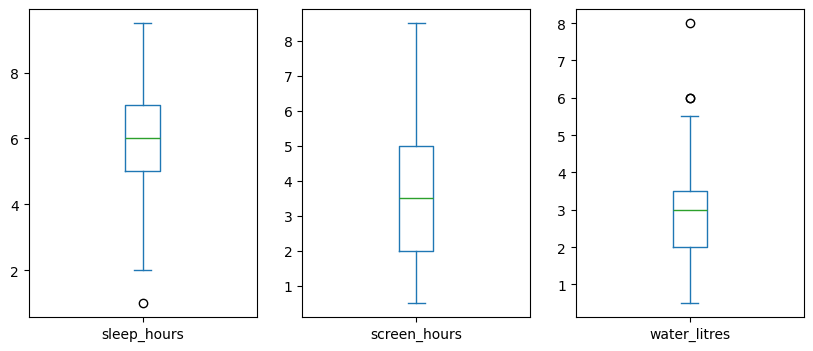

In [16]:
df[cols].plot(kind="box", subplots=True, layout=(1, 3), figsize=(10, 4));

In [17]:
for c in cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    df.loc[(df[c] < low) | (df[c] > high), c] = np.nan

print(df[cols].isna().sum())

sleep_hours     4
screen_hours    3
water_litres    6
dtype: int64


In [18]:
before = df[cols].copy()          # keep the unfilled version for comparison

for c in cols:
    df[c] = df[c].fillna(df[c].median())

print(df[cols].isna().sum())      # should be 0, 0, 0

sleep_hours     0
screen_hours    0
water_litres    0
dtype: int64


In [19]:
print(before.describe().round(2))
print(df[cols].describe().round(2))

       sleep_hours  screen_hours  water_litres
count        96.00         97.00         94.00
mean          5.86          3.79          2.78
std           1.54          1.88          1.05
min           2.00          0.50          0.50
25%           5.00          2.00          2.00
50%           6.00          3.50          3.00
75%           7.00          5.00          3.38
max           9.50          8.50          5.50
       sleep_hours  screen_hours  water_litres
count       100.00        100.00        100.00
mean          5.87          3.78          2.79
std           1.51          1.86          1.02
min           2.00          0.50          0.50
25%           5.00          2.00          2.00
50%           6.00          3.50          3.00
75%           7.00          5.00          3.00
max           9.50          8.50          5.50


In [20]:
df.to_csv("cleaned_file.csv", index=False)
df.shape

(100, 25)

In [21]:
male = df[df["gender"] == "Male"]
female = df[df["gender"] == "Female"]
#step-1. set alpha
alpha = 0.05

In [ ]:
# Test 1: F-test (compares two variances)

# Question: is the spread of the data the same for males and females?

# H₀: σ²(male) = σ²(female)
# H₁: the variances are different 
# Statistic: F = variance of group 1 ÷ variance of group 2, with (n₁−1, n₂−1) degrees of freedom
#step-2: calculate stats(n, mean, std dev, variance)
n1 = len(male)
n2 = len(female)
mean1 = male['screen_hours'].mean()
mean2 = female['screen_hours'].mean()
variance1 = ((male['screen_hours'] - mean1)**2).sum()/(n1-1)
variance2 = ((female['screen_hours'] - mean2)**2).sum() / (n2 - 1)
std_dev1 = variance1 ** 0.5
std_dev2 = variance2 ** 0.5
#step-3: calculate f and dof
f = max(variance1, variance2)/min(variance1, variance2)
if variance1 > variance2:
    dof1 = n1 - 1
    dof2 = n2 - 1
else:
    dof1 = n2 - 1
    dof2 = n1 - 1

# step 4: critical value, read from the F-table
# alpha/2 = 0.025 (right tail), df = (56, 42)
f_critical = 1.803
print("f-value: ", round(f, 3), ", dof: ", (dof1, dof2))
print(f_critical)
if f > f_critical:
    print("H0 rejected")
else:
    print("Fail to reject H0")

f-value:  1.783 , dof:  (56, 42)
1.803
Fail to reject H0


In [23]:
# Test 2: t-test (compares two means)
# We are using independent 2 sample t-test because we are comparing male and female screen hours.
#Step 1: H₀: μ_male = μ_female.
# H₁: μ_male ≠ μ_female.

#step-2: stats
print(n1, n2, round(mean1, 4), round(mean2, 4), round(variance1, 4), round(variance2, 4), sep = '\n')

#step-3: calculate standard error:
std_error1 = variance1/n1
std_error2 = variance2/n2
t_std_error = (std_error1 + std_error2) ** 0.5
print('Standard error: ', round(t_std_error, 3))

#step-4: Calculate t:
t = (mean1 - mean2)/t_std_error
print('t-value: ', round(t, 3))

#step-5: calculate dof
dof3 = n1 + n2 - 2
print('Dof: ', dof3)
t_critical = 1.984
print('Critical t-value: ', t_critical)

#step-6: Comparison
if abs(t) > t_critical:
    print("Reject H0")
else:
    print("Fail to reject H0")

57
43
4.1754
3.2605
4.0312
2.2607
Standard error:  0.351
t-value:  2.606
Dof:  98
Critical t-value:  1.984
Reject H0


In [24]:
# Test 3: Z-test (compares a mean with a known value)

# Question: is the average sleep of students different from 7 hours?

# Statistic: z = (x̄ − μ₀) ÷ (s ÷ √n), z = (sample mean − reference value) ÷ standard error, 
# so it counts how many standard errors your sample mean sits away from the reference value. The further from 0, the harder it is to blame chance.
# Z is appropriate here because n = 100 (at least 30). The population SD is unknown, so I used the sample SD.
# H₀: μ = 7
# H₁: μ ≠ 7
n = len(df['sleep_hours'])
print('n: ')
mean = df['sleep_hours'].mean()
print("Mean: ", round(mean, 2))
variance = (((df['sleep_hours'] - mean))**2).sum()/ (n-1)
print('Variance: ', round(variance, 2))
std_dev = variance ** 0.5
print("standard deviation: ", round(std_dev, 2))
std_error = std_dev/(n ** 0.5)
print('standard error: ', round(std_error, 2))
z = (7- mean)/std_error
print('Z-value: ', round(z, 3))
critical_z = 1.96 #should have been +-1.96
print('Critical Z-value: ')
if abs(z) > critical_z:
    print('Reject H0')
else:
    print('Fail to reject H0')

n: 
Mean:  5.87
Variance:  2.29
standard deviation:  1.51
standard error:  0.15
Z-value:  7.466
Critical Z-value: 
Reject H0


In [34]:
# Test 4: Chi-square test (two categorical variables)
#step-1
#H0: gender and meal regularity are independent
#H1: they are associated

#step-1:
# meal_m = (male['meal_regularity'] == '3 regular meals').sum()
# print('Male + 3 regular meals:',meal_m)
# meal_m2 = (male['meal_regularity'] == 'Irregular/Random eating times').sum()
# print('Male + irregular meals:',meal_m2)
# meal_m3 = (male['meal_regularity'] == 'Skip 1 meal daily').sum()
# print('Male + skip meal:',meal_m3)
# meal_f = (female['meal_regularity'] == 'Skip 1 meal daily').sum()
# print('Female + skip meal:',meal_f)
# meal_f2 = (female['meal_regularity'] == 'Irregular/Random eating times').sum()
# print('Female + irregular:',meal_f2)
# meal_f3 = (female['meal_regularity'] == '3 regular meals').sum()
# print('Female + 3 regular meals:',meal_f3)
# sum_reg = meal_m + meal_f3
# print('\nSum of regular meals:',sum_reg)
# sum_irr = meal_m2 + meal_f2
# print('Sum of irregular meals:', sum_irr)
# sum_skip = meal_m3 + meal_f
# print('Sum of skipping meal:', sum_skip)
# male_sum = meal_m + meal_m2 + meal_m3
# print('Sum of male column:', male_sum)
# female_sum = meal_f + meal_f2 + meal_f3
# print('Sum of female column:', female_sum)
# total_sum = male_sum + female_sum
# print('\nTotal sum:', total_sum)
observed = pd.crosstab(df['gender'], df['meal_regularity'])
print(observed)

row_totals = observed.sum(axis=1)     # one total per gender
col_totals = observed.sum(axis=0)     # one total per meal category
N = observed.values.sum()             # grand total

print(row_totals)
print(col_totals)
print('N =', N)
#step-2: expected table = (rows * columns)/total
expected = observed.copy().astype(float)
for i in observed.index:
    for j in observed.columns:
        expected.loc[i,  j] = (row_totals[i] * col_totals[j])/ N
print(expected.round(2))

#step-3: Step 4: Chi-square statistic. For every cell compute (O − E)² ÷ E, then add them all up:
#χ² = Σ (O − E)² ÷ E
chi_value = 0
for i in observed.index:
    for j in observed.columns:
        cell_value = ((observed.loc[i,j] - expected.loc[i,j]) ** 2)/expected.loc[i,j]
        chi_value = chi_value + cell_value
print('Chi- value:', round(chi_value, 2))

#step-4: dof
dof4 = (len(observed.index) - 1) * (len(observed.columns) - 1)
print('dof: ', dof4)

chi_critical = 5.991
print('Critical chi-value:', chi_critical)

#step-5: comparison
if chi_value > chi_critical:
    print('Reject H0')
else:
    print('Fail to reject H0')

meal_regularity  3 regular meals  Irregular/Random eating times  \
gender                                                            
Female                        12                             20   
Male                          27                             10   

meal_regularity  Skip 1 meal daily  
gender                              
Female                          11  
Male                            20  
gender
Female    43
Male      57
dtype: int64
meal_regularity
3 regular meals                  39
Irregular/Random eating times    30
Skip 1 meal daily                31
dtype: int64
N = 100
meal_regularity  3 regular meals  Irregular/Random eating times  \
gender                                                            
Female                     16.77                           12.9   
Male                       22.23                           17.1   

meal_regularity  Skip 1 meal daily  
gender                              
Female                       13.33  
Male        

EXPERIMENT-4

In [ ]:
#LINEAR REGRESSION
#Step 1: Model and hypothesis
# Model: energy = b₀ + b₁ × sleep

# Step 2: n, mean of x, mean of y
x = df['sleep_hours']          # predictor
y = df['evening_energy']       # response

n = len(x)
total = 0
for i in x:
    total = (total + i)
mean_x = total/len(x)
print('Mean of x:', round(mean_x, 2))

total = 0
for i in y:
    total = (total + i)
mean_y = total/len(y)
print('Mean of y:', round(mean_y, 2))
print('n =', n)

#step-3: calculate deviation
dev_x = x - mean_x
dev_y = y - mean_y
print('Deviation of x:', round(dev_x, 2))
print('Deviation of y:', round(dev_y, 2))

#step-4: product of deviation:
prod_dev = dev_x * dev_y
print('Product of deviations:', prod_dev.head())

#step-5: sum of product of dev:
sum_prod_dev = 0
for i in prod_dev:
    sum_prod_dev = sum_prod_dev + i
print('Sum of product of deviations:', round(sum_prod_dev, 4))

#step-6:sum of square of dev of x:
sum_sqofx = 0
for i in dev_x:
    sum_sqofx = sum_sqofx + (i**2)
print('Sum of square of deviations of x:', round(sum_sqofx, 4))

#step-7: calculate slope:
slope = (sum_prod_dev)/sum_sqofx
print('Slope:', round(slope, 4))

#step-8:intersection
c = mean_y - (slope * mean_x)
print('Intersection:', round(c,4))



Mean of x: 5.87
Mean of y: 2.87
n = 100
Deviation of x: 0    -0.87
1     1.13
2    -0.87
3    -0.87
4     2.63
      ... 
95   -0.37
96    1.63
97   -0.87
98    0.63
99    0.13
Name: sleep_hours, Length: 100, dtype: float64
Deviation of y: 0     0.13
1     0.13
2    -1.87
3    -0.87
4     1.13
      ... 
95    2.13
96    0.13
97   -0.87
98    0.13
99   -1.87
Name: evening_energy, Length: 100, dtype: float64
Product of deviations: 0   -0.1131
1    0.1469
2    1.6269
3    0.7569
4    2.9719
dtype: float64
Sum of product of deviations: 45.31
Sum of square of deviations of x: 226.81
Slope: 0.1998
Intersection: 1.6973


EXPERIMET-5:

In [49]:
import matplotlib.pyplot as plt

# stress score = total of the five stress/anxiety questions (each answered 1 to 5)
stress_cols = ['stress_anxious', 'racing_thoughts', 'concentration', 'low_motivation', 'irritability']
df['stress_score'] = df[stress_cols].sum(axis=1)

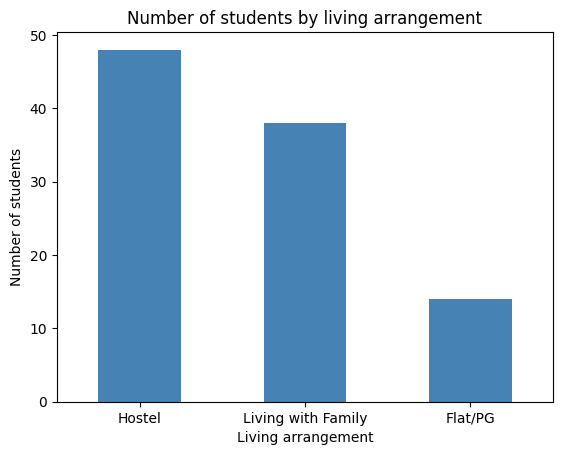

In [ ]:
# How are students split across living arrangements?
counts = df['living_arrangement'].value_counts()

counts.plot(kind='bar', color='steelblue')
plt.title('Number of students by living arrangement')
plt.xlabel('Living arrangement')
plt.ylabel('Number of students')
plt.xticks(rotation=0)
plt.show()

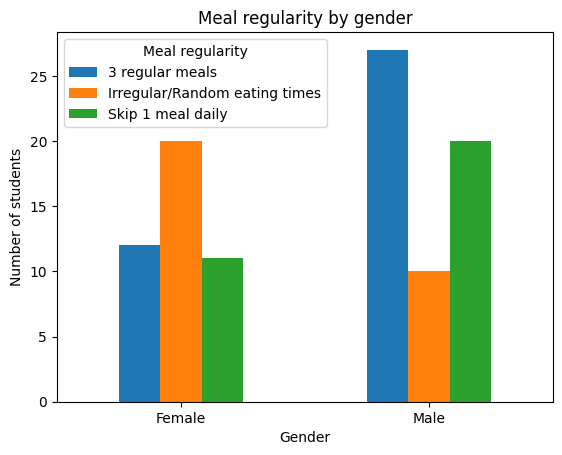

In [51]:
# Do meal habits differ by gender?
table = pd.crosstab(df['gender'], df['meal_regularity'])

table.plot(kind='bar')
plt.title('Meal regularity by gender')
plt.xlabel('Gender')
plt.ylabel('Number of students')
plt.xticks(rotation=0)
plt.legend(title='Meal regularity')
plt.show()

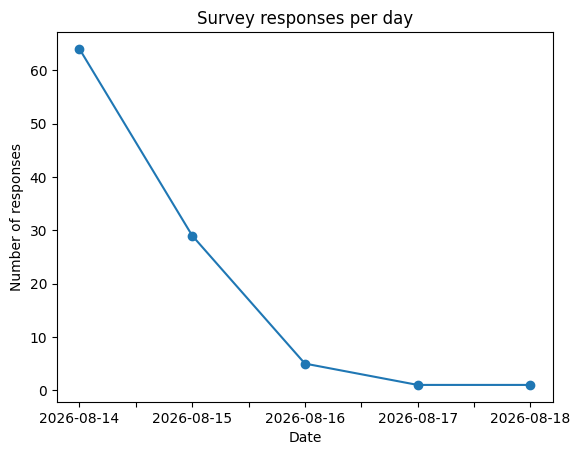

In [52]:
# How did responses come in over time?
per_day = df['submitted_at'].dt.date.value_counts().sort_index()
per_day.index = per_day.index.astype(str)     # dates as text, so each date gets one tick

per_day.plot(kind='line', marker='o')
plt.title('Survey responses per day')
plt.xlabel('Date')
plt.ylabel('Number of responses')
plt.show()

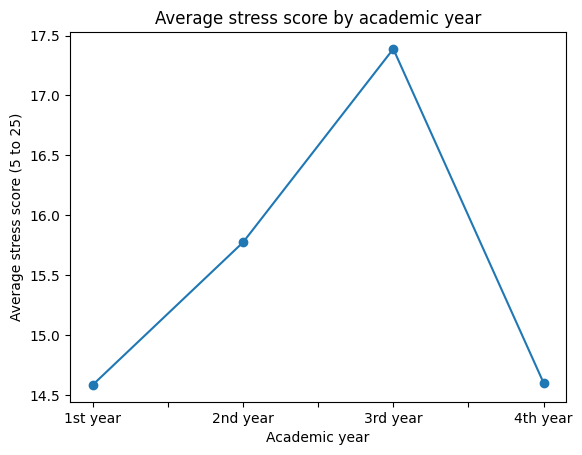

In [53]:
# Does stress differ across academic years?
avg_stress = df.groupby('academic_year')['stress_score'].mean()

avg_stress.plot(kind='line', marker='o')
plt.title('Average stress score by academic year')
plt.xlabel('Academic year')
plt.ylabel('Average stress score (5 to 25)')
plt.show()

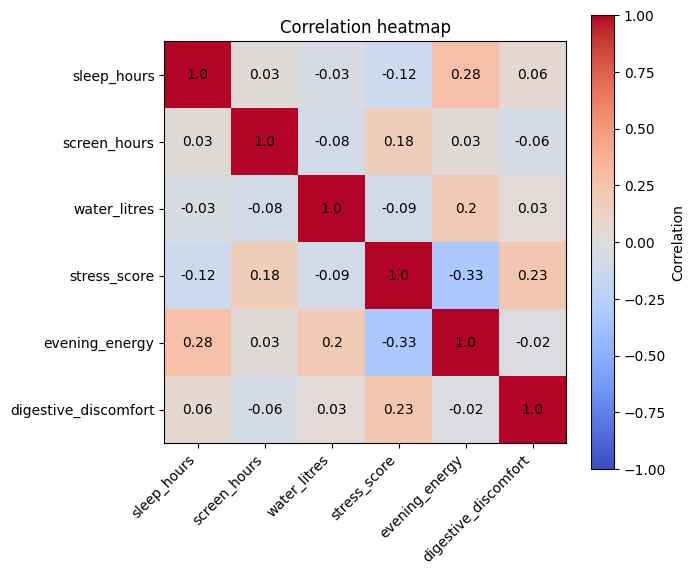

In [54]:
# Which variables move together?
heat_cols = ['sleep_hours', 'screen_hours', 'water_litres',
             'stress_score', 'evening_energy', 'digestive_discomfort']
corr = df[heat_cols].corr()          # table of correlations between every pair

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)     # colours from -1 (blue) to +1 (red)
plt.colorbar(label='Correlation')
plt.xticks(range(len(heat_cols)), heat_cols, rotation=45, ha='right')
plt.yticks(range(len(heat_cols)), heat_cols)

# write the number inside each square
for i in range(len(heat_cols)):
    for j in range(len(heat_cols)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center')

plt.title('Correlation heatmap')
plt.tight_layout()
plt.show()

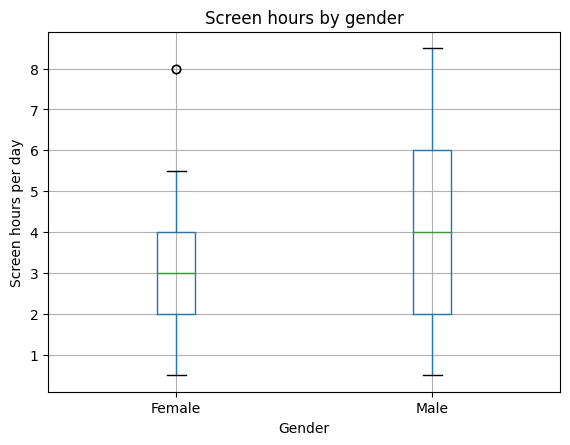

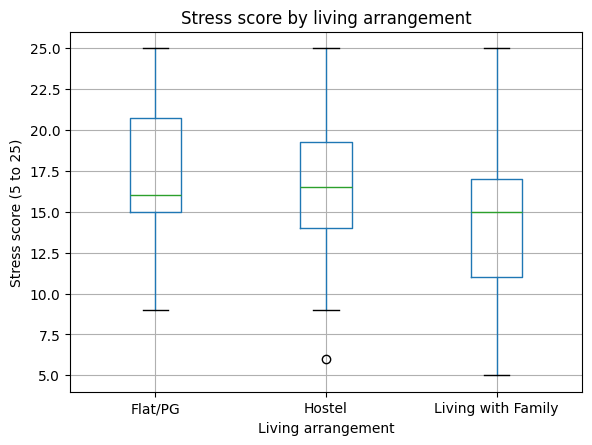

In [55]:
# How do the spread and middle of a variable compare across groups?
df.boxplot(column='screen_hours', by='gender')
plt.suptitle('')                        # removes the extra automatic title
plt.title('Screen hours by gender')
plt.xlabel('Gender')
plt.ylabel('Screen hours per day')
plt.show()

df.boxplot(column='stress_score', by='living_arrangement')
plt.suptitle('')
plt.title('Stress score by living arrangement')
plt.xlabel('Living arrangement')
plt.ylabel('Stress score (5 to 25)')
plt.show()